In [197]:
from IPython.core.display import display, HTML
display(HTML("<style>.container { width:100% !important; }</style>"))

/var/folders/bx/bzgj6qhd5_l2_b7d0v7r7r7r0000gn/T/ipykernel_1764/3777615979.py:1: DeprecationWarning: Importing display from IPython.core.display is deprecated since IPython 7.14, please import from IPython display
  from IPython.core.display import display, HTML


# Lab | Natural Language Processing
### SMS: SPAM or HAM

### Let's prepare the environment

In [200]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split

In [201]:
import nltk
nltk.download('punkt')
nltk.download('punkt_tab')  # required by newer NLTK

[nltk_data] Downloading package punkt to
[nltk_data]     /Users/ricardomontoyasantos/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /Users/ricardomontoyasantos/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

- Read Data for the Fraudulent Email Kaggle Challenge
- Reduce the training set to speead up development. 

In [203]:
## Read Data for the Fraudulent Email Kaggle Challenge
data = pd.read_csv(r"/Users/ricardomontoyasantos/Desktop/DSML/W17D3-lab-natural-language-processing/data/kg_train.csv",encoding='latin-1')
# Reduce the training set to speed up development. 
# Modify for final system
data = data.head(1000)
print(data.shape)
data.fillna("",inplace=True)

(1000, 2)


### Let's divide the training and test set into two partitions

In [205]:
data_train, data_val = train_test_split(
    data, 
    test_size=0.2, 
    random_state=42
)

In [206]:
from nltk.tokenize import word_tokenize
data['tokens'] = data['text'].astype(str).apply(word_tokenize)

## Data Preprocessing

In [208]:
import string
from nltk.corpus import stopwords
print(string.punctuation)
print(stopwords.words("english")[100:110])
from nltk.stem.snowball import SnowballStemmer
snowball = SnowballStemmer('english')

!"#$%&'()*+,-./:;<=>?@[\]^_`{|}~
['needn', "needn't", 'no', 'nor', 'not', 'now', 'o', 'of', 'off', 'on']


## Now, we have to clean the html code removing words

- First we remove inline JavaScript/CSS
- Then we remove html comments. This has to be done before removing regular tags since comments can contain '>' characters
- Next we can remove the remaining tags

In [210]:
import re

def clean_html(raw_html: str) -> str:
    # 1) Remove inline JavaScript/CSS
    x = re.sub(r'(?is)<script[^>]*>.*?</script>', '', raw_html)
    x = re.sub(r'(?is)<style[^>]*>.*?</style>',  '', x)

    # 2) Remove HTML comments (do this before generic tag removal)
    x = re.sub(r'(?s)<!--.*?-->', '', x)

    # 3) Remove remaining tags
    x = re.sub(r'(?s)<[^>]+>', '', x)

    return x

data_train['text_clean'] = data_train['text'].apply(lambda raw : clean_html(raw))
data_val['text_clean'] = data_val['text'].apply(lambda raw : clean_html(raw))

- Remove all the special characters
    
- Remove numbers
    
- Remove all single characters
 
- Remove single characters from the start

- Substitute multiple spaces with single space

- Remove prefixed 'b'

- Convert to Lowercase

In [212]:
def clean_basic(text: str) -> str:
    
    x = text

    # 1) Remove all the special characters (keep letters, digits, spaces)
    x = re.sub(r'[^A-Za-z0-9\s]', ' ', x)

    # 2) Remove numbers
    x = re.sub(r'\d+', ' ', x)

    # 3) Remove all single characters
    x = re.sub(r'\b[A-Za-z]\b', ' ', x)

    # 4) Remove single characters from the start
    x = re.sub(r'^\s*[A-Za-z]\s+', '', x)

    # 5) Substitute multiple spaces with single space
    x = re.sub(r'\s+', ' ', x).strip()

    # 6) Remove prefixed 'b'
    x = re.sub(r'^b\s+', '', x)

    # 7) Convert to lowercase
    x = x.lower()

    return x
    
data_train['text_clean'] = data_train['text_clean'].apply(lambda raw : clean_basic(raw))
data_val['text_clean'] = data_val['text_clean'].apply(lambda raw : clean_basic(raw))

In [213]:
data_train

,text,label,text_clean
29,"----------- REGARDS, MR NELSON SMITH.KINDLY RE...",1,regards mr nelson smith kindly reply me on my ...
535,I have not been able to reach oscar this am. W...,0,have not been able to reach oscar this am we a...
695,; Huma Abedin B6I'm checking with Pat on the 5...,0,huma abedin checking with pat on the will work...
557,I can have it announced here on Monday - can't...,0,can have it announced here on monday can today
836,BANK OF AFRICAAGENCE SAN PEDRO14 BP 1210 S...,1,bank of africaagence san pedro bp san pedro co...
...,...,...,...
106,7653 2612ADAMA IBRAHIM________________________...,1,adama ibrahim tout savoir sur la curit de votr...
270,What does that mean for our schedules?,0,what does that mean for our schedules
860,"Dear Friend,My Compliment to you,I guess this ...",1,dear friend my compliment to you guess this le...
435,Dear PRESIDENT=2FDIRECTOR=2C My name is Mr=2E ...,1,dear president fdirector my name is mr micheal...


## Now let's work on removing stopwords
Remove the stopwords.

In [215]:
# Your code
from nltk.corpus import stopwords
stopwords.words("english")

from nltk.tokenize import RegexpTokenizer
tok = RegexpTokenizer(r"[A-Za-z']+")
STOP = set(stopwords.words('english'))

data_train['text_no_stops'] = data_train['text_clean'].astype(str).apply(lambda s: ' '.join([w for w in tok.tokenize(s.lower()) if w not in STOP]))
data_val['text_no_stops'] = data_val['text_clean'].astype(str).apply(lambda s: ' '.join([w for w in tok.tokenize(s.lower()) if w not in STOP]))

## Tame Your Text with Lemmatization
Break sentences into words, then use lemmatization to reduce them to their base form (e.g., "running" becomes "run"). See how this creates cleaner data for analysis!

In [217]:
# Your code

nltk.download('wordnet') # wordnet is the most well known lemmatizer for english
nltk.download('omw-1.4')
from nltk.stem import WordNetLemmatizer
from nltk.corpus import wordnet

def lemmatize_text(text):

    lemmatizer = WordNetLemmatizer()
    
    # Tokenize text into words
    words = word_tokenize(text)
    
    # Apply lemmatization to each word
    lemmatized_words = [lemmatizer.lemmatize(word) for word in words]
    
    # Join words back into text
    return ' '.join(lemmatized_words)

[nltk_data] Downloading package wordnet to
[nltk_data]     /Users/ricardomontoyasantos/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     /Users/ricardomontoyasantos/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


In [218]:
# lemmatization
data_train['preprocessed_text'] = data_train['text_no_stops'].apply(lemmatize_text)
data_val['preprocessed_text'] = data_val['text_no_stops'].apply(lemmatize_text)

## Bag Of Words
Let's get the 10 top words in ham and spam messages (**EXPLORATORY DATA ANALYSIS**)

In [220]:
# Separate ham and spam
ham_words = ' '.join(data_train[data_train['label'] == 1]['preprocessed_text']).split()
spam_words = ' '.join(data_train[data_train['label'] == 0]['preprocessed_text']).split()

# Count word frequencies and return top N
ham_freq = pd.Series(ham_words).value_counts()
spam_freq = pd.Series(spam_words).value_counts()

In [245]:
# Convert to DataFrame for plotting
ham_df = pd.DataFrame(ham_freq).reset_index()
spam_df = pd.DataFrame(spam_freq).reset_index()

In [247]:
ham_df.columns=['word', 'count']
spam_df.columns=['word', 'count']

In [276]:
ham_df_top10 = ham_df.sort_values(by=['count'],ascending=False ).head(10)
spam_df_top10 = spam_df.sort_values(by=['count'],ascending=False).head(10)

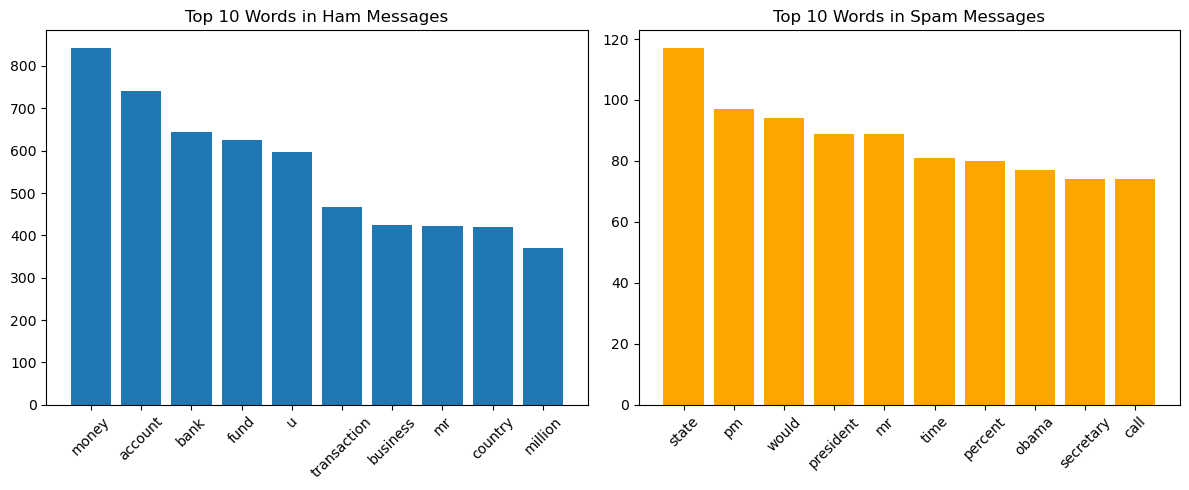

In [280]:
# Plotting
plt.figure(figsize=(12, 5))

# Ham plot
plt.subplot(1, 2, 1)
plt.bar(ham_df_top10['word'], ham_df_top10['count'])
plt.title('Top 10 Words in Ham Messages')
plt.xticks(rotation=45)

# Spam plot
plt.subplot(1, 2, 2)
plt.bar(spam_df_top10 ['word'], spam_df_top10['count'], color='orange')
plt.title('Top 10 Words in Spam Messages')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

## Extra features

In [251]:
# We add to the original dataframe two additional indicators (money symbols and suspicious words).
money_simbol_list = "|".join(["euro","dollar","pound","€",r"\$"])
suspicious_words = "|".join(["free","cheap","sex","money","account","bank","fund","transfer","transaction","win","deposit","password"])

data_train['money_mark'] = data_train['preprocessed_text'].str.contains(money_simbol_list)*1
data_train['suspicious_words'] = data_train['preprocessed_text'].str.contains(suspicious_words)*1
data_train['text_len'] = data_train['preprocessed_text'].apply(lambda x: len(x)) 

data_val['money_mark'] = data_val['preprocessed_text'].str.contains(money_simbol_list)*1
data_val['suspicious_words'] = data_val['preprocessed_text'].str.contains(suspicious_words)*1
data_val['text_len'] = data_val['preprocessed_text'].apply(lambda x: len(x)) 

data_train.head()

,text,label,text_clean,text_no_stops,preprocessed_text,money_mark,suspicious_words,text_len
29,"----------- REGARDS, MR NELSON SMITH.KINDLY RE...",1,regards mr nelson smith kindly reply me on my ...,regards mr nelson smith kindly reply private e...,regard mr nelson smith kindly reply private em...,0,0,79
535,I have not been able to reach oscar this am. W...,0,have not been able to reach oscar this am we a...,able reach oscar supposed send pdb receive,able reach oscar supposed send pdb receive,0,0,42
695,; Huma Abedin B6I'm checking with Pat on the 5...,0,huma abedin checking with pat on the will work...,huma abedin checking pat work jack jake rest a...,huma abedin checking pat work jack jake rest a...,0,0,76
557,I can have it announced here on Monday - can't...,0,can have it announced here on monday can today,announced monday today,announced monday today,0,0,22
836,BANK OF AFRICAAGENCE SAN PEDRO14 BP 1210 S...,1,bank of africaagence san pedro bp san pedro co...,bank africaagence san pedro bp san pedro cote ...,bank africaagence san pedro bp san pedro cote ...,1,1,1050


## How would you create a Bag of Words with the CountVectorizer method?

In [282]:
data_train['preprocessed_text']

29     regard mr nelson smith kindly reply private em...
535           able reach oscar supposed send pdb receive
695    huma abedin checking pat work jack jake rest a...
557                               announced monday today
836    bank africaagence san pedro bp san pedro cote ...
                             ...                        
106    adama ibrahim tout savoir sur la curit de votr...
270                                        mean schedule
860    dear friend compliment guess letter may come s...
435    dear president fdirector name mr micheal ipenz...
102    let know today tomorrow work would rather find...
Name: preprocessed_text, Length: 800, dtype: object

In [290]:
# Your code
from sklearn.feature_extraction.text import CountVectorizer
import pandas as pd

data_train['preprocessed_text']
# Step 1: Initialize CountVectorizer
vectorizer = CountVectorizer()

# Step 2: Fit and transform the messages
bow_train = vectorizer.fit_transform(data_train['preprocessed_text'])
bow_val = vectorizer.transform(data_val['preprocessed_text'])

# Step 3: Convert to DataFrame for better readability
bow_train_df = pd.DataFrame(bow_train.toarray(), columns=vectorizer.get_feature_names_out())
bow_val_df = pd.DataFrame(bow_val.toarray(), columns=vectorizer.get_feature_names_out())

print(f"Bag of Words matrix shape:")
print(f"Training: {bow_train.shape} (documents x vocabulary)")
print(f"Validation: {bow_val.shape}")

Bag of Words matrix shape:
Training: (800, 28167) (documents x vocabulary)
Validation: (200, 28167)


## TF-IDF

- Load the vectorizer

- Vectorize all dataset

- print the shape of the vetorized dataset

In [302]:
data_concatenated

,text,label,text_clean,text_no_stops,preprocessed_text,money_mark,suspicious_words,text_len,text_lemm
29,"----------- REGARDS, MR NELSON SMITH.KINDLY RE...",1,regards mr nelson smith kindly reply me on my ...,regards mr nelson smith kindly reply private e...,regard mr nelson smith kindly reply private em...,0.0,0.0,79.0,NaN
535,I have not been able to reach oscar this am. W...,0,have not been able to reach oscar this am we a...,able reach oscar supposed send pdb receive,able reach oscar supposed send pdb receive,0.0,0.0,42.0,NaN
695,; Huma Abedin B6I'm checking with Pat on the 5...,0,huma abedin checking with pat on the will work...,huma abedin checking pat work jack jake rest a...,huma abedin checking pat work jack jake rest a...,0.0,0.0,76.0,NaN
557,I can have it announced here on Monday - can't...,0,can have it announced here on monday can today,announced monday today,announced monday today,0.0,0.0,22.0,NaN
836,BANK OF AFRICAAGENCE SAN PEDRO14 BP 1210 S...,1,bank of africaagence san pedro bp san pedro co...,bank africaagence san pedro bp san pedro cote ...,bank africaagence san pedro bp san pedro cote ...,1.0,1.0,1050.0,NaN
...,...,...,...,...,...,...,...,...,...
408,Sorry yes exactlyWe have shy tomorrow at 10am ...,0,sorry yes exactlywe have shy tomorrow at am too,sorry yes exactlywe shy tomorrow,sorry yes exactlywe shy tomorrow,NaN,NaN,NaN,"[s, o, r, r, y, , y, e, s, , e, x, a, c, t, ..."
332,DEAR=2CGOOD DAY=2EI KNOW THIS MESSAGE WILL COM...,1,dear cgood day ei know this message will come ...,dear cgood day ei know message come suprise co...,dear cgood day ei know message come suprise co...,NaN,NaN,NaN,"[d, e, a, r, , c, g, o, o, d, , d, a, y, , ..."
208,FYI,0,fyi,fyi,fyi,NaN,NaN,NaN,"[f, y, i]"
613,Greetings Dear Friend Please Permit me to cont...,1,greetings dear friend please permit me to cont...,greetings dear friend please permit contact me...,greeting dear friend please permit contact med...,NaN,NaN,NaN,"[g, r, e, e, t, i, n, g, s, , d, e, a, r, , ..."


In [308]:
# Your code

data_concatenated = pd.concat([data_train,data_test])

# 1. Initialize the TF-IDF Vectorizer
tfidf_vectorizer = TfidfVectorizer()

# 2. Fit and transform the full dataset (vectorize all messages)
tfidf_matrix = tfidf_vectorizer.fit_transform(data_concatenated['preprocessed_text'])

# 3. Print the shape of the resulting matrix
print("TF-IDF matrix shape:", tfidf_matrix.shape)

TF-IDF matrix shape: (1000, 29931)


### Extra Task (optional) - Implement a SPAM/HAM classifier

https://www.kaggle.com/t/b384e34013d54d238490103bc3c360ce

Use a MultinimialNB with default parameters.

Your task is to **find the most relevant features**.

For example, you can test the following options and check which of them performs better:
- Using "Bag of Words" only
- Using "TF-IDF" only
- Bag of Words + extra flags (money_mark, suspicious_words, text_len)
- TF-IDF + extra flags


You can work with teams of two persons (recommended).

In [ ]:
# Your code